<a href="https://colab.research.google.com/github/ShivaL52/FGCT6020-AI-Food-Image-Generator/blob/main/01_base_model_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

PyTorch: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
!pip install -q diffusers transformers accelerate

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

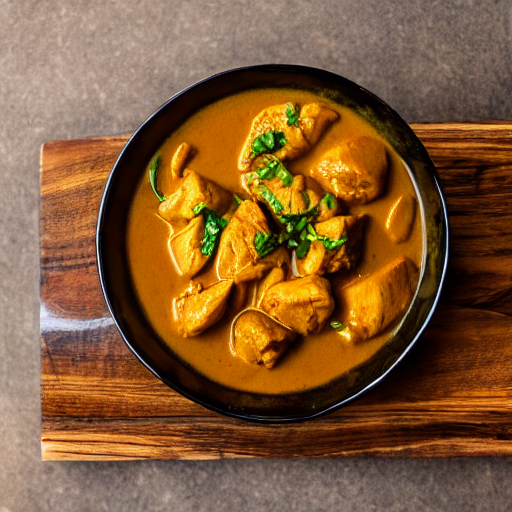

In [3]:
from diffusers import StableDiffusionPipeline
import torch

# Load the base Stable Diffusion model onto the GPU
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    dtype=torch.float16
).to("cuda")

# A fixed seed makes the result repeatable
generator = torch.Generator("cuda").manual_seed(42)

prompt = "a professional food photograph of chicken curry in a bowl, restaurant advertising"
image = pipe(prompt, generator=generator, num_inference_steps=30).images[0]

image.save("base_sd_test.png")
image